# Ejercicio 4 — NovaMarket: clientes y fidelización (Python)
**Learning Activity 3 · Data Intelligence Challenge · Individual**

Problema: reconocer clientes de alto valor y oportunidades de recuperación.

## E — EXTRAER (evidencia E4.1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Leemos el CSV original. utf-8-sig elimina el BOM del inicio del archivo.
df = pd.read_csv("../data/original/04_NovaMarket_Clientes.csv", encoding="utf-8-sig")
df_original = df.copy()   # copia del estado original para comparar después

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (36, 6)


,ID_Cliente,Segmento,Ciudad,Compras_90d,Gasto_90d_COP,Dias_Ultima_Compra
0,C001,Frecuente,Medellín,6,480000.0,11
1,C002,Corporativo,Cali,3,105000.0,22
2,C003,Nuevo,Bogotá,8,640000.0,33
3,C004,Frecuente,Medellín,5,175000.0,44
4,C005,Corporativo,Cali,2,160000.0,55


In [2]:
df.info()   # tipos de dato y no nulos por columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Cliente          36 non-null     object 
 1   Segmento            36 non-null     object 
 2   Ciudad              36 non-null     object 
 3   Compras_90d         36 non-null     int64  
 4   Gasto_90d_COP       35 non-null     float64
 5   Dias_Ultima_Compra  36 non-null     int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 1.8+ KB


In [3]:
df.isna().sum()   # datos faltantes por columna (esperamos 1 en Gasto_90d_COP)

ID_Cliente            0
Segmento              0
Ciudad                0
Compras_90d           0
Gasto_90d_COP         1
Dias_Ultima_Compra    0
dtype: int64

In [4]:
# Revisión de anomalías antes de transformar
print("Ciudades (con sus variantes):")
print(df["Ciudad"].value_counts())
print()
print("Compras negativas:")
print(df[df["Compras_90d"] < 0])

Ciudades (con sus variantes):
Ciudad
Medellín    12
Bogotá      12
Cali        11
bogotá       1
Name: count, dtype: int64

Compras negativas:
   ID_Cliente     Segmento Ciudad  Compras_90d  Gasto_90d_COP  \
31       C032  Corporativo   Cali           -1        35000.0   

    Dias_Ultima_Compra  
31                  79  


## T — TRANSFORMAR (evidencia E4.2)

In [5]:
# 1) Normalizar Ciudad: quitar espacios y dejar la primera letra en mayúscula ('bogotá ' -> 'Bogotá')
df["Ciudad"] = df["Ciudad"].str.strip().str.title()

# 2) Convertir a número. errors="coerce": lo que no sea número queda NaN (no se inventa).
for c in ["Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3) Compras negativas = inválidas (no se puede comprar -1 veces) -> NaN
#    El gasto faltante ya es NaN desde la lectura, así que queda marcado como inválido.
n_compras_neg = (df["Compras_90d"] < 0).sum()
df.loc[df["Compras_90d"] < 0, "Compras_90d"] = np.nan
print("Compras negativas marcadas como inválidas:", n_compras_neg)

Compras negativas marcadas como inválidas: 1


In [6]:
# 4) Clasificación según las reglas del laboratorio (el orden de los if importa):
def clasificar(r):
    # Si falta algún dato esencial -> no se puede clasificar
    if pd.isna(r["Compras_90d"]) or pd.isna(r["Gasto_90d_COP"]) or pd.isna(r["Dias_Ultima_Compra"]):
        return "No clasificable"
    # Alto valor: gasto >= 250.000 COP Y al menos 3 compras
    if r["Gasto_90d_COP"] >= 250000 and r["Compras_90d"] >= 3:
        return "Alto valor"
    # Si no es alto valor y lleva más de 60 días sin comprar -> En seguimiento
    if r["Dias_Ultima_Compra"] > 60:
        return "En seguimiento"
    # Todos los demás
    return "Otros"

# apply(axis=1) aplica la función fila por fila
df["Categoria"] = df.apply(clasificar, axis=1)
df["Categoria"].value_counts()

Categoria
Otros              15
Alto valor         14
En seguimiento      5
No clasificable     2
Name: count, dtype: int64

In [7]:
# Comparación ORIGINAL vs PREPARADO de las filas modificadas (trazabilidad)
comp = df_original.merge(df, on="ID_Cliente", suffixes=("_orig", "_limpio"))
filtro = (comp["Ciudad_orig"] != comp["Ciudad_limpio"]) | \
         (comp["Compras_90d_orig"].fillna(-999) != comp["Compras_90d_limpio"].fillna(-999)) | \
         (comp["Gasto_90d_COP_orig"].isna())
comp.loc[filtro, ["ID_Cliente", "Ciudad_orig", "Ciudad_limpio", "Compras_90d_orig",
                  "Compras_90d_limpio", "Gasto_90d_COP_orig", "Categoria"]]

,ID_Cliente,Ciudad_orig,Ciudad_limpio,Compras_90d_orig,Compras_90d_limpio,Gasto_90d_COP_orig,Categoria
10,C011,bogotá,Bogotá,8,8.0,640000.0,Alto valor
20,C021,Bogotá,Bogotá,2,2.0,NaN,No clasificable
31,C032,Cali,Cali,-1,NaN,35000.0,No clasificable


## L — LOAD / CARGAR (evidencia E4.3)

In [8]:
# Exportamos el CSV depurado (en carpeta distinta al original)
df.to_csv("../data/limpio/NovaMarket_Clientes_Limpio.csv", index=False)
pd.read_csv("../data/limpio/NovaMarket_Clientes_Limpio.csv").head()

,ID_Cliente,Segmento,Ciudad,Compras_90d,Gasto_90d_COP,Dias_Ultima_Compra,Categoria
0,C001,Frecuente,Medellín,6.0,480000.0,11,Alto valor
1,C002,Corporativo,Cali,3.0,105000.0,22,Otros
2,C003,Nuevo,Bogotá,8.0,640000.0,33,Alto valor
3,C004,Frecuente,Medellín,5.0,175000.0,44,Otros
4,C005,Corporativo,Cali,2.0,160000.0,55,Otros


## Analizar y comunicar (evidencia E4.4)

In [9]:
# --- Cantidad de clientes por categoría ---
conteo = df["Categoria"].value_counts()
print(conteo)
print("Total:", conteo.sum())

Categoria
Otros              15
Alto valor         14
En seguimiento      5
No clasificable     2
Name: count, dtype: int64
Total: 36


In [10]:
# --- Gasto total y promedio VÁLIDO (los NaN no se cuentan) ---
print(f"Gasto total (válido): {df['Gasto_90d_COP'].sum():,.0f} COP")
print(f"Gasto promedio (sobre {df['Gasto_90d_COP'].notna().sum()} clientes con gasto válido): "
      f"{df['Gasto_90d_COP'].mean():,.0f} COP")

Gasto total (válido): 9,880,000 COP
Gasto promedio (sobre 35 clientes con gasto válido): 282,286 COP


In [11]:
# --- Gasto promedio y compras promedio por categoría ---
df.groupby("Categoria").agg(
    clientes=("ID_Cliente", "count"),
    gasto_prom=("Gasto_90d_COP", "mean"),
    compras_prom=("Compras_90d", "mean"),
    dias_prom_ultima=("Dias_Ultima_Compra", "mean"),
).round(1)

,clientes,gasto_prom,compras_prom,dias_prom_ultima
Categoria,,,,
Alto valor,14,491428.6,6.1,38.6
En seguimiento,5,119000.0,3.4,76.8
No clasificable,2,35000.0,2.0,64.0
Otros,15,158000.0,4.0,36.0


In [12]:
# --- Los 5 clientes con mayor gasto ---
# OJO: hay empates en 640.000 COP; nlargest toma los primeros 5 en orden de aparición.
top5 = df.nlargest(5, "Gasto_90d_COP")[["ID_Cliente", "Segmento", "Ciudad", "Compras_90d",
                                         "Gasto_90d_COP", "Dias_Ultima_Compra", "Categoria"]]
print("Clientes con gasto máximo (incluye empates):", (df["Gasto_90d_COP"] == df["Gasto_90d_COP"].max()).sum())
top5

Clientes con gasto máximo (incluye empates): 5


,ID_Cliente,Segmento,Ciudad,Compras_90d,Gasto_90d_COP,Dias_Ultima_Compra,Categoria
2,C003,Nuevo,Bogotá,8.0,640000.0,33,Alto valor
10,C011,Corporativo,Bogotá,8.0,640000.0,30,Alto valor
18,C019,Frecuente,Medellín,8.0,640000.0,27,Alto valor
26,C027,Nuevo,Bogotá,8.0,640000.0,24,Alto valor
34,C035,Corporativo,Cali,8.0,640000.0,21,Alto valor


In [13]:
# --- Clientes En seguimiento (oportunidad de recuperación) ---
seg = df[df["Categoria"] == "En seguimiento"][["ID_Cliente", "Segmento", "Ciudad", "Compras_90d",
                                               "Gasto_90d_COP", "Dias_Ultima_Compra"]]
print("Clientes en seguimiento:", len(seg))
seg.sort_values("Dias_Ultima_Compra", ascending=False)

Clientes en seguimiento: 5


,ID_Cliente,Segmento,Ciudad,Compras_90d,Gasto_90d_COP,Dias_Ultima_Compra
7,C008,Corporativo,Cali,1.0,35000.0,88
15,C016,Frecuente,Medellín,1.0,35000.0,85
23,C024,Nuevo,Bogotá,1.0,35000.0,82
5,C006,Nuevo,Bogotá,7.0,245000.0,66
13,C014,Corporativo,Cali,7.0,245000.0,63


In [14]:
# --- Clientes NO clasificables (hay que documentar por qué) ---
df[df["Categoria"] == "No clasificable"]

,ID_Cliente,Segmento,Ciudad,Compras_90d,Gasto_90d_COP,Dias_Ultima_Compra,Categoria
20,C021,Nuevo,Bogotá,2.0,NaN,49,No clasificable
31,C032,Corporativo,Cali,NaN,35000.0,79,No clasificable


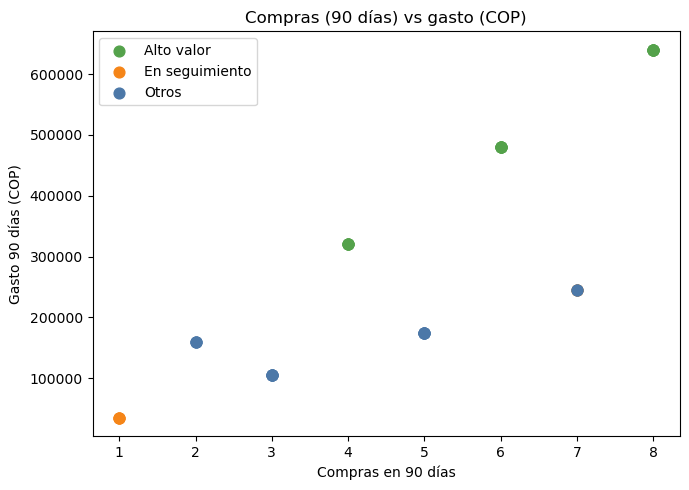

In [15]:
# --- GRÁFICO 1: dispersión compras vs gasto, coloreada por categoría ---
colores = {"Alto valor": "#54A24B", "En seguimiento": "#F58518", "Otros": "#4C78A8"}
fig, ax = plt.subplots(figsize=(7, 5))
for cat, color in colores.items():
    sub = df[df["Categoria"] == cat]
    ax.scatter(sub["Compras_90d"], sub["Gasto_90d_COP"], label=cat, color=color, s=60)
ax.set_title("Compras (90 días) vs gasto (COP)")
ax.set_xlabel("Compras en 90 días")
ax.set_ylabel("Gasto 90 días (COP)")
ax.legend()
plt.tight_layout()
plt.savefig("../graficos/ej4_dispersion_compras_gasto.png", dpi=150)
plt.show()

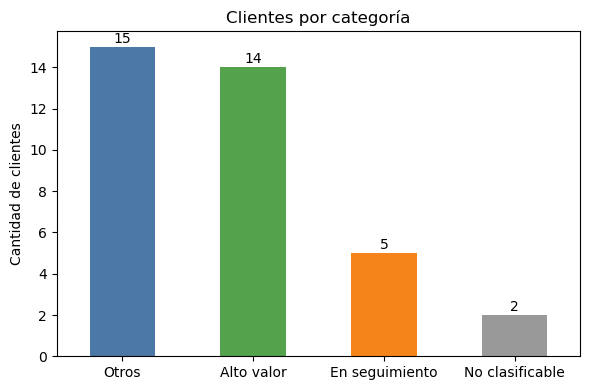

In [16]:
# --- GRÁFICO 2: clientes por segmento (categoría) ---
fig, ax = plt.subplots(figsize=(6, 4))
conteo.plot(kind="bar", ax=ax, color=["#4C78A8", "#54A24B", "#F58518", "#999999"][:len(conteo)])
ax.set_title("Clientes por categoría")
ax.set_ylabel("Cantidad de clientes")
ax.set_xlabel("")
for i, v in enumerate(conteo):
    ax.text(i, v + 0.2, str(v), ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../graficos/ej4_clientes_por_categoria.png", dpi=150)
plt.show()

## Anomalías detectadas (documentar en el informe)
| ID | Anomalía | Tratamiento |
|---|---|---|
| C011 | Ciudad `'bogotá '` (espacio y minúscula) | Normalizada a `Bogotá` |
| C021 | `Gasto_90d_COP` vacío | Queda NaN → *No clasificable* |
| C032 | `Compras_90d = -1` | Marcado NaN (inválido) → *No clasificable* |